# RiMEA 12a: Position of Goal Cells

This notebook demonstrates the current public implementation of RiMEA Test 12a. We load one base two-room scenario (150 agents in room 1), move the goal in room 2 by a distance `a`, and measure how long room 1 needs to empty through the bottleneck.

The measured quantity is the **room-1 clearance time**: the time at which the last agent crosses the bottleneck line, a vertical PedPy measurement line at `x = 10` directly in the wall opening between the rooms. It is not the total evacuation time of the building.

RiMEA expectation: the clearance time is usually shortest when the goal lies directly behind the bottleneck; it increases with the distance `a` and then levels off at a constant value.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 12:52 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pedpy

from jupedsim_scenarios import load_scenario, run_scenario


In [3]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#f7f7f5",
        "axes.edgecolor": "#3a3a3a",
        "axes.labelcolor": "#1d1d1d",
        "axes.titleweight": "bold",
        "xtick.color": "#1d1d1d",
        "ytick.color": "#1d1d1d",
        "font.size": 11,
    }
)

SCENARIO_DIR = Path("scenario_files") / "Rimea-12a-goal-position.zip"
A_VALUES = [0.2, *range(1, 10), 9.8]
MEASUREMENT_LINE = pedpy.MeasurementLine([(10.0, 4.5), (10.0, 5.5)])
SAMPLE_A_VALUES = [0.2, 5, 9.8]
SWEEP_SEEDS = [40, 41, 42]


## Load the Base Scenario

The scenario directory contains the shared two-room geometry and the initial crowd distribution. The notebook deep-copies the loaded raw scenario before moving the goal, so each run stays independent.

In [4]:
base_scenario = load_scenario(str(SCENARIO_DIR))
print(base_scenario.summary())

Scenario: scenario_files/Rimea-12a-goal-position.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~150
    jps-distributions_0: 150 agents


## Helper Functions

We represent the goal as a thin exit strip inside room 2. The left edge of that strip is placed at `x = 10.2 + a`, but we keep the sweep strictly inside room 2, from `a = 0.2` to `a = 9.8`.

In [5]:
def make_exit(distance_a: float) -> dict:
    left_x = 10.2 + float(distance_a)
    right_x = left_x + 0.2
    return {
        "jps-exits_0": {
            "type": "polygon",
            "coordinates": [[left_x, 0], [right_x, 0], [right_x, 10], [left_x, 10], [left_x, 0]],
            "enable_throughput_throttling": False,
            "max_throughput": 0,
        }
    }


def room1_evacuation_time(traj: pedpy.TrajectoryData):
    nt, crossing_frames = pedpy.compute_n_t(
        traj_data=traj,
        measurement_line=MEASUREMENT_LINE,
    )
    if len(crossing_frames) == 0:
        raise ValueError("No agents crossed the room-1 measurement line.")
    last_crossing_frame = int(crossing_frames["frame"].max())
    return nt, crossing_frames, last_crossing_frame / traj.frame_rate


def run_goal_variant(base, distance_a: float, seed: int = 42) -> dict:
    variant = base.copy()
    variant.source_path = f"rimea-12a-a{distance_a}"
    variant.raw["exits"] = make_exit(distance_a)
    result = run_scenario(variant, seed=seed)
    traj = pedpy.TrajectoryData(
        result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy(),
        frame_rate=result.frame_rate,
    )
    nt, crossing_frames, room1_time = room1_evacuation_time(traj)
    metrics = dict(result.metrics)
    metrics["room1_evacuation_time"] = room1_time
    result.cleanup()
    return {
        "a": distance_a,
        "trajectory": traj,
        "walkable_area": pedpy.WalkableArea(variant.walkable_polygon),
        "goal": variant.raw["exits"]["jps-exits_0"]["coordinates"],
        "nt": nt,
        "crossing_frames": crossing_frames,
        "metrics": metrics,
        "room1_evacuation_time": room1_time,
    }


## Run the Goal-Position Sweep

The trajectory plots below use one deterministic run per distance. For the final dependence plot, we average over three seeds to reduce noise in the tail of the curve.

In [6]:
%%capture
runs = [run_goal_variant(base_scenario, distance_a, seed=42) for distance_a in A_VALUES]
sweep_runs = []
for distance_a in A_VALUES:
    seed_times = [
        run_goal_variant(base_scenario, distance_a, seed=seed)["room1_evacuation_time"]
        for seed in SWEEP_SEEDS
    ]
    sweep_runs.append(
        {
            "a": distance_a,
            "mean_room1_time": float(np.mean(seed_times)),
            "std_room1_time": float(np.std(seed_times)),
            "seed_times": seed_times,
        }
    )

summary_rows = [
    {
        "a_m": run["a"],
        "mean_room1_evacuation_time_s": round(run["mean_room1_time"], 2),
        "std_room1_evacuation_time_s": round(run["std_room1_time"], 2),
        "seed_times_s": [round(value, 2) for value in run["seed_times"]],
    }
    for run in sweep_runs
]
summary_rows

## Plot Geometries and Trajectories for Selected Distances

The three panels below show how the goal moves through room 2. The dashed line is the PedPy measurement line at `x = 10`, and the green strip is the goal location for that scenario.

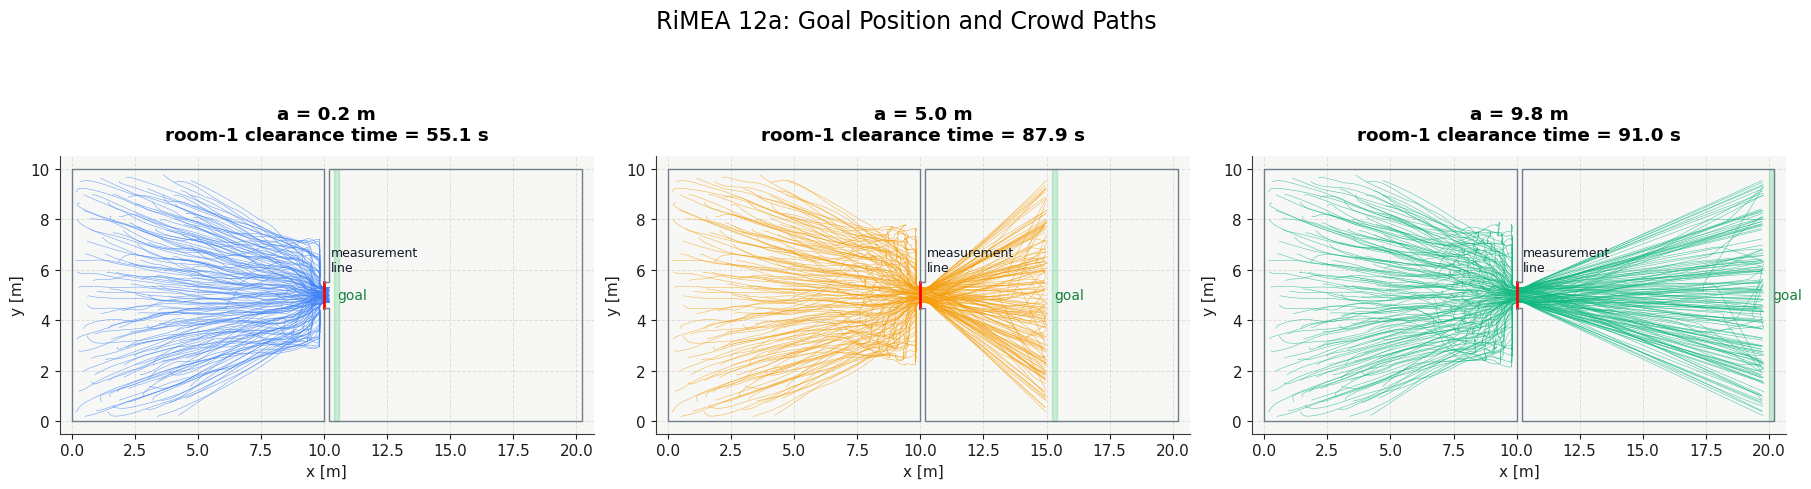

In [7]:
selected_runs = [run for run in runs if run["a"] in SAMPLE_A_VALUES]
trajectory_colors = {0.2: "#3B82F6", 5: "#F59E0B", 9.8: "#10B981"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

for ax, run in zip(axes, selected_runs):
    color = trajectory_colors[run["a"]]
    pedpy.plot_measurement_setup(
        traj=run["trajectory"],
        walkable_area=run["walkable_area"],
        measurement_lines=[MEASUREMENT_LINE],
        axes=ax,
        traj_alpha=0.72,
        traj_width=0.4,
        ml_width=2,
        ml_alpha=0.2,
        traj_color=color,
        ml_color="red",
    ).set_aspect("equal")
    goal_xy = np.asarray(run["goal"])
    ax.plot(goal_xy[:2, 0], goal_xy[:2, 1], alpha=0)
    ax.fill(goal_xy[:, 0], goal_xy[:, 1], color="#22C55E", alpha=0.22)
    ax.text(10.25, 5.85, "measurement\nline", color="#111827", fontsize=9, va="bottom")
    ax.text(goal_xy[0, 0] + 0.12, 5.0, "goal", color="#15803D", fontsize=10, va="center")
    ax.set_title(
        f"a = {run['a']:.1f} m\n"
        f"room-1 clearance time = {run['room1_evacuation_time']:.1f} s",
        pad=12,
    )
    ax.set_xlim(-0.5, 20.7)
    ax.set_ylim(-0.5, 10.5)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("RiMEA 12a: Goal Position and Crowd Paths", fontsize=17, y=1.02)
plt.show()

## Plot Room-1 Clearance Time vs. Goal Distance

The chart below shows the mean time when the last agent from room 1 crosses the measurement line at `x = 10`, plotted against the goal distance `a` in room 2. The error bars show the standard deviation across the three seeds in `SWEEP_SEEDS`.

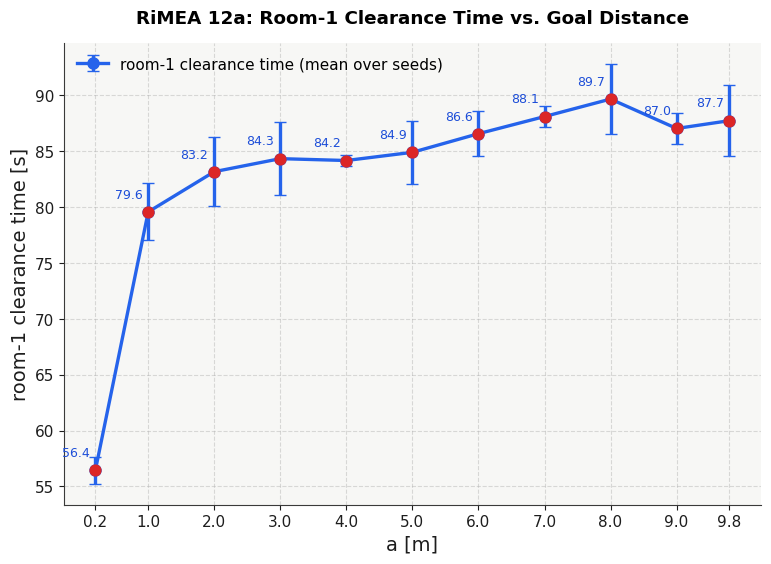

In [8]:
a_values = np.array([run["a"] for run in sweep_runs], dtype=float)
room1_times = np.array([run["mean_room1_time"] for run in sweep_runs], dtype=float)
room1_std = np.array([run["std_room1_time"] for run in sweep_runs], dtype=float)

fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(
    a_values,
    room1_times,
    yerr=room1_std,
    color="#2563EB",
    linewidth=2.4,
    marker="o",
    markersize=8,
    capsize=4,
    label="room-1 clearance time (mean over seeds)",
)
ax.scatter(a_values, room1_times, color="#DC2626", s=60, zorder=3)

for a_value, evac_time in zip(a_values, room1_times):
    ax.annotate(
        f"{evac_time:.1f}",
        (a_value-0.3, evac_time),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        color="#1D4ED8",
        fontsize=9,
    )

ax.set_title("RiMEA 12a: Room-1 Clearance Time vs. Goal Distance", pad=14)
ax.set_xlabel("a [m]", fontsize=14)
ax.set_ylabel("room-1 clearance time [s]", fontsize=14)
ax.set_xticks(a_values)
ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

## Single-Seed Curve (Seed 42, as in the Automated Test)

The automated test `TestRiMEA12aGoalPosition` uses seed 42 only and uses the same `a` grid as this notebook and checks (1) that every `a` >= 1 m has a larger clearance time than `a` = 0.2 m, and (2) that the mean over the plateau (all `a` >= 4 m) is not below the value at `a` = 1 m. There is no step-by-step monotonicity check because the plateau fluctuates. The curve below is the seed-42 sweep. RiMEA expects the clearance time to rise with `a` and then level off.

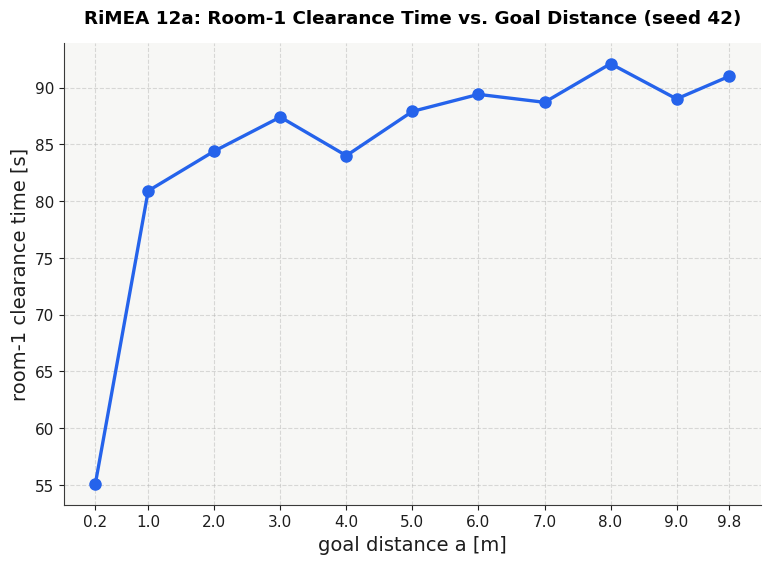

{0.2: 55.1,
 1.0: 80.9,
 2.0: 84.4,
 3.0: 87.4,
 4.0: 84.0,
 5.0: 87.9,
 6.0: 89.4,
 7.0: 88.7,
 8.0: 92.1,
 9.0: 89.0,
 9.8: 91.0}

In [9]:
seed42_a = np.array([run["a"] for run in runs], dtype=float)
seed42_times = np.array([run["room1_evacuation_time"] for run in runs], dtype=float)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(seed42_a, seed42_times, color="#2563EB", linewidth=2.4, marker="o", markersize=8)
ax.set_title("RiMEA 12a: Room-1 Clearance Time vs. Goal Distance (seed 42)", pad=14)
ax.set_xlabel("goal distance a [m]", fontsize=14)
ax.set_ylabel("room-1 clearance time [s]", fontsize=14)
ax.set_xticks(seed42_a)
ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()
{float(a): round(float(t), 1) for a, t in zip(seed42_a, seed42_times)}

In [10]:
by_a = dict(zip(seed42_a.tolist(), seed42_times.tolist()))
t_near = by_a[0.2]
t_one = by_a[1.0]
plateau_mean = float(np.mean([t for a, t in by_a.items() if a >= 4.0]))
above_near = all(t > t_near for a, t in by_a.items() if a >= 1.0)
plateau_ok = plateau_mean >= t_one
print(f"(1) every a >= 1 m exceeds a = 0.2 m ({t_near:.1f} s): {above_near}")
print(f"(2) plateau mean (a >= 4 m) {plateau_mean:.1f} s >= value at a = 1 m ({t_one:.1f} s): {plateau_ok}")
assert above_near and plateau_ok

(1) every a >= 1 m exceeds a = 0.2 m (55.1 s): True
(2) plateau mean (a >= 4 m) 88.9 s >= value at a = 1 m (80.9 s): True
